In [4]:
import numpy as np
import tensorflow as tf
from sklearn.model_selection import train_test_split
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import Perceptron
from sklearn.metrics import accuracy_score,classification_report,confusion_matrix

from tensorflow.keras.models import Sequential
#this lets me build neural network layer by layer in keras
from tensorflow.keras.layers import Dense #dense makes the final prediction
from tensorflow.keras.layers import Conv2D #conv2d extract features
from tensorflow.keras.layers import Flatten #flatter reshape kore

from tensorflow.keras.layers import MaxPool2D #maxpooling kore- size reduce
from tensorflow.keras.layers import Dropout 

from tensorflow.keras.utils import to_categorical #converts numerical into labels into one hot encoding format

In [5]:
# Use the dataset path already available in the notebook kernel.
# import kagglehub

# # Download latest version
# path = kagglehub.dataset_download("bhavikjikadara/dog-and-cat-classification-dataset")

# print("Path to dataset files:", path)
data_path = path
print("Using dataset path:", data_path)

Using Colab cache for faster access to the 'dog-and-cat-classification-dataset' dataset.
Path to dataset files: /kaggle/input/dog-and-cat-classification-dataset
Using dataset path: /kaggle/input/dog-and-cat-classification-dataset


In [6]:
import os

dataset_path = "/kaggle/input/dog-and-cat-classification-dataset"

for root, dirs, files in os.walk(dataset_path):
    print("Folder:", root)
    print("Subfolders:", dirs[:10])
    print("Number of files:", len(files))
    print("Sample files:", files[:5])
    print("-" * 50)

Folder: /kaggle/input/dog-and-cat-classification-dataset
Subfolders: ['PetImages']
Number of files: 0
Sample files: []
--------------------------------------------------
Folder: /kaggle/input/dog-and-cat-classification-dataset/PetImages
Subfolders: ['Dog', 'Cat']
Number of files: 0
Sample files: []
--------------------------------------------------
Folder: /kaggle/input/dog-and-cat-classification-dataset/PetImages/Dog
Subfolders: []
Number of files: 12499
Sample files: ['7981.jpg', '6234.jpg', '1269.jpg', '3863.jpg', '6241.jpg']
--------------------------------------------------
Folder: /kaggle/input/dog-and-cat-classification-dataset/PetImages/Cat
Subfolders: []
Number of files: 12499
Sample files: ['7981.jpg', '6234.jpg', '1269.jpg', '3863.jpg', '6241.jpg']
--------------------------------------------------


In [9]:
from pathlib import Path

dataset_path = Path(
    "/kaggle/input/dog-and-cat-classification-dataset"
)

# Find folders named Cat/Cats and Dog/Dogs
class_pairs = []

for path in dataset_path.rglob("*"):
    if path.is_dir():
        children = {
            p.name.lower(): p
            for p in path.iterdir()
            if p.is_dir()
        }

        cat_dir = next(
            (children[n] for n in ["cat", "cats"] if n in children),
            None
        )
        dog_dir = next(
            (children[n] for n in ["dog", "dogs"] if n in children),
            None
        )

        if cat_dir and dog_dir:
            class_pairs.append((path, cat_dir, dog_dir))

if not class_pairs:
    raise FileNotFoundError("Could not find Cat and Dog class folders.")

data_dir = str(class_pairs[0][0])

print("Dataset directory:", data_dir)
for parent, cat_dir, dog_dir in class_pairs:
    print("Cat folder:", cat_dir)
    print("Dog folder:", dog_dir)

Dataset directory: /kaggle/input/dog-and-cat-classification-dataset/PetImages
Cat folder: /kaggle/input/dog-and-cat-classification-dataset/PetImages/Cat
Dog folder: /kaggle/input/dog-and-cat-classification-dataset/PetImages/Dog


In [10]:
IMG_SIZE = (128, 128)
BATCH_SIZE = 32
SEED = 42

train_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.30,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    class_names=["Cat", "Dog"]
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.30,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    class_names=["Cat", "Dog"]
)

print("Classes:", train_ds.class_names)

Found 24998 files belonging to 2 classes.
Using 17499 files for training.
Found 24998 files belonging to 2 classes.
Using 7499 files for validation.
Classes: ['Cat', 'Dog']


In [11]:
normalization_layer = tf.keras.layers.Rescaling(1./255)

train_ds = train_ds.map(
    lambda images, labels: (
        normalization_layer(images), labels
    )
)

val_ds = val_ds.map(
    lambda images, labels: (
        normalization_layer(images), labels
    )
)

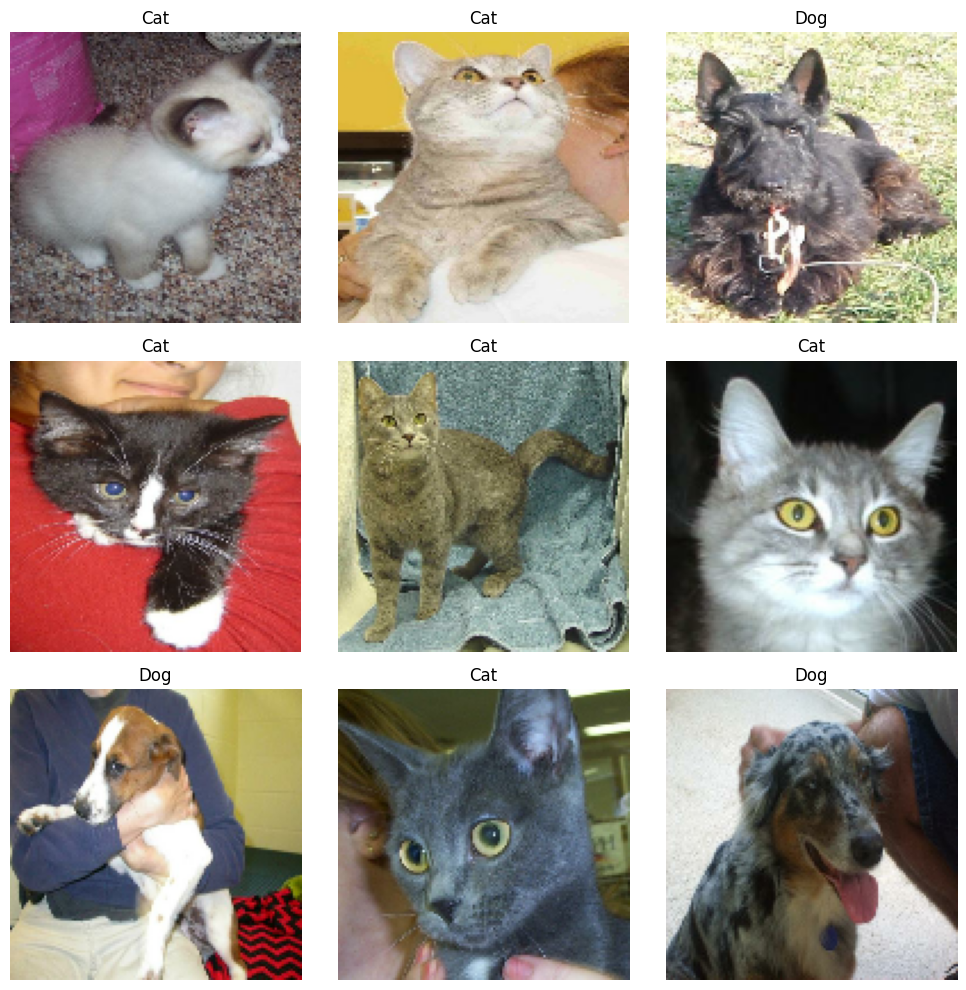

In [12]:
class_names = ["Cat", "Dog"]

plt.figure(figsize=(10, 10))

for images, labels in train_ds.take(1):
    for i in range(9):
        plt.subplot(3, 3, i + 1)

        plt.imshow(images[i].numpy())

        label = int(labels[i].numpy()[0])
        plt.title(class_names[label])
        plt.axis("off")

plt.tight_layout()
plt.show()

In [13]:
for images, labels in train_ds.take(1):
    print("Images shape:", images.shape)
    print("Labels shape:", labels.shape)

    print("Minimum pixel value:", tf.reduce_min(images).numpy())
    print("Maximum pixel value:", tf.reduce_max(images).numpy())

Images shape: (32, 128, 128, 3)
Labels shape: (32, 1)
Minimum pixel value: 0.0
Maximum pixel value: 1.0


In [14]:
autotune = tf.data.AUTOTUNE

# Skip image files that TensorFlow cannot decode.
train_ds = train_ds.ignore_errors()
val_ds = val_ds.ignore_errors()

train_ds = train_ds.prefetch(buffer_size=autotune)
val_ds = val_ds.prefetch(buffer_size=autotune)

In [ ]:
cnn = Sequential([
    Conv2D(
        32,
        kernel_size=(3, 3),
        activation="relu",
        input_shape=(*IMG_SIZE, 3),
    ),
    MaxPool2D(pool_size=(2, 2)),
    Conv2D(64, kernel_size=(3, 3), activation="relu"),
    MaxPool2D(pool_size=(2, 2)),
    Flatten(),
    Dense(128, activation="relu"),
    Dropout(0.5),
    Dense(1, activation="sigmoid"),
])
cnn.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_8 (Conv2D)               │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_4 (Flatten)             │ (None, 57600)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 128)            │     7,372,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,392,449 (28.20 MB)

 Trainable params: 7,392,449 (28.20 MB)

 Non-trainable params: 0 (0.00 B)

In [18]:
cnn.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"],
)

In [22]:
history = cnn.fit(
    train_ds,
    validation_data=val_ds,
    epochs=40,
)

Epoch 1/40
543/543 ━━━━━━━━━━━━━━━━━━━━ 29s 54ms/step - accuracy: 0.8254 - loss: 0.3875 - val_accuracy: 0.8416 - val_loss: 0.3673
Epoch 2/40
543/543 ━━━━━━━━━━━━━━━━━━━━ 30s 56ms/step - accuracy: 0.8268 - loss: 0.3891 - val_accuracy: 0.8302 - val_loss: 0.4074
Epoch 3/40
543/543 ━━━━━━━━━━━━━━━━━━━━ 32s 58ms/step - accuracy: 0.8355 - loss: 0.3813 - val_accuracy: 0.8372 - val_loss: 0.3856
Epoch 4/40
543/543 ━━━━━━━━━━━━━━━━━━━━ 41s 58ms/step - accuracy: 0.8366 - loss: 0.3781 - val_accuracy: 0.8413 - val_loss: 0.3708
Epoch 5/40
543/543 ━━━━━━━━━━━━━━━━━━━━ 32s 59ms/step - accuracy: 0.8353 - loss: 0.3757 - val_accuracy: 0.8388 - val_loss: 0.3737
Epoch 6/40
543/543 ━━━━━━━━━━━━━━━━━━━━ 33s 60ms/step - accuracy: 0.8316 - loss: 0.3752 - val_accuracy: 0.8371 - val_loss: 0.3882
Epoch 7/40
543/543 ━━━━━━━━━━━━━━━━━━━━ 32s 58ms/step - accuracy: 0.8365 - loss: 0.3663 - val_accuracy: 0.8183 - val_loss: 0.4307
Epoch 8/40
543/543 ━━━━━━━━━━━━━━━━━━━━ 30s 55ms/step - accuracy: 0.8393 - loss: 0.3674 - 

In [23]:
acc_cnn=cnn.evaluate(val_ds,verbose=0)[1]
acc_cnn

0.8655950427055359

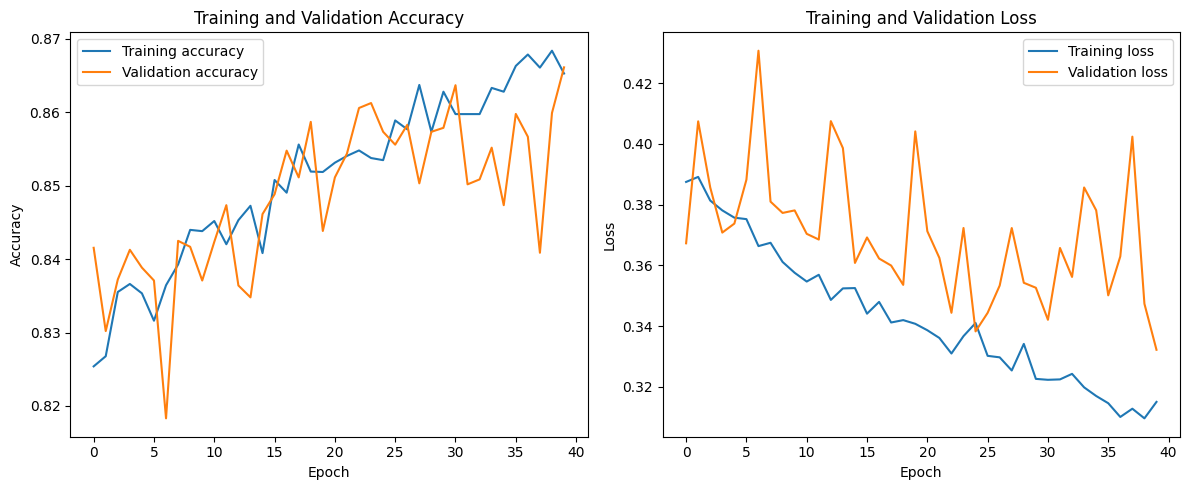

In [24]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training accuracy")
plt.plot(history.history["val_accuracy"], label="Validation accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()

plt.tight_layout()
plt.show()